# Automated QA System: Low-Latency Fruit Freshness Detection
## Executive Summary & Business Value

Proyek ini mendesain arsitektur Deep Learning klasifikasi citra untuk **mengotomatisasi inspeksi mutu buah di meja pemaketan (*packing station*)** operasional *quick-commerce*.

Tujuan: **memitigasi kerugian finansial** (biaya *refund* logistik + *customer churn*) dengan memblokir produk cacat sebelum terkirim ke konsumen.


# Import Library

In [ ]:
import subprocess, sys, os
import time, warnings, datetime, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from dataclasses import dataclass
import kagglehub
import tensorflow as tf
from tensorflow.keras import layers, applications, callbacks, optimizers, regularizers

print("Memeriksa dataset...")
KAGGLE_PATH = kagglehub.dataset_download("ulnnproject/food-freshness-dataset")
print(f"Dataset siap di: {KAGGLE_PATH}")

@dataclass
class PackingStationConfig:
    dataset_root: str         = str(Path(KAGGLE_PATH) / "Dataset")
    cache_df_path: str        = "dataset_metadata.parquet"
    checkpoint_path: str      = "fruit_qa_best.keras"
    log_dir: str              = "logs"
    img_size: tuple           = (224, 224)
    channels: int             = 3
    val_split: float          = 0.20
    batch_size: int           = 32
    seed: int                 = 42

    epochs_phase1: int        = 8
    lr_phase1: float          = 1e-3

    epochs_phase2: int        = 12
    lr_phase2: float          = 1e-5
    unfreeze_from_layer: int  = 30

    dropout_rate_1: float     = 0.4
    dropout_rate_2: float     = 0.3
    dense_units: int          = 256
    l2_reg: float             = 0.01

    latency_threshold_ms: int = 100
    latency_warmup_runs: int  = 10
    latency_benchmark_runs: int = 50

config = PackingStationConfig()
tf.random.set_seed(config.seed)
os.makedirs(config.log_dir, exist_ok=True)
print("Konfigurasi siap.")

Memeriksa dataset...
Using Colab cache for faster access to the 'food-freshness-dataset' dataset.
Dataset siap di: /kaggle/input/food-freshness-dataset
Konfigurasi siap.


---
## 1. EDA — Exploratory Data Analysis

> **⚠️ WAJIB BACA PLOT** sebelum lanjut.
> Tujuan: Cek distribusi kelas, kualitas gambar, dan apakah ada class imbalance.

  Total Gambar    : 71,318
  Total Kelas     : 26
  Imbalance Ratio : 41.84x
            Class  Count     Category
      FreshTomato  13681        Fresh
      FreshOrange  10831        Fresh
      FreshCarrot   9899        Fresh
      RottenApple   4437 Rotten/Stale
     RottenBanana   4038 Rotten/Stale
     RottenTomato   4014 Rotten/Stale
      FreshBanana   3473        Fresh
       FreshApple   3431        Fresh
     RottenOrange   3292 Rotten/Stale
     RottenCarrot   2419 Rotten/Stale
     RottenPotato   1387 Rotten/Stale
      FreshPotato   1151        Fresh
    FreshCucumber   1104        Fresh
   RottenCucumber   1014 Rotten/Stale
   FreshCapciscum    990        Fresh
   RottenCapsicum    901 Rotten/Stale
       FreshOkara    635        Fresh
  FreshBellpepper    611        Fresh
       FreshMango    605        Fresh
  FreshStrawberry    603        Fresh
 RottenStrawberry    596 Rotten/Stale
      RottenMango    593 Rotten/Stale
 RottenBellpepper    591 Rotten/Stale
RottenBitte

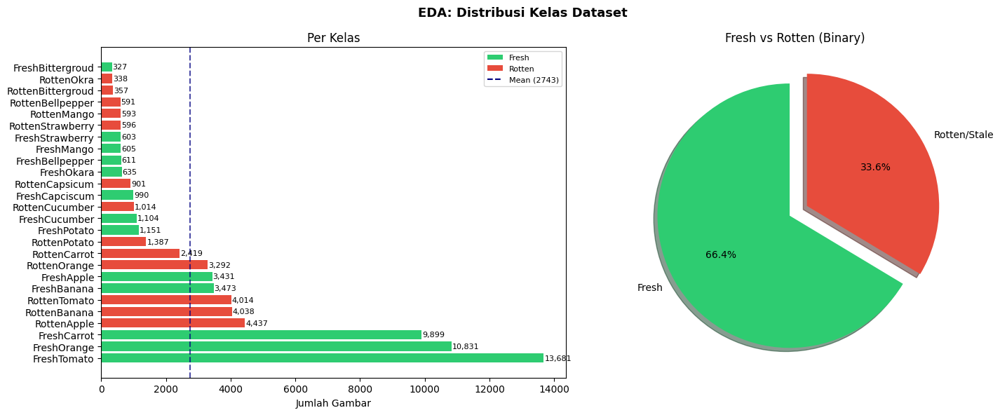

In [ ]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
data_dist = []

fresh_dir = Path("/kaggle/input/food-freshness-dataset/Dataset/Fresh")
rotten_dir = Path("/kaggle/input/food-freshness-dataset/Dataset/Rotten")

if fresh_dir.exists():
    for sub_dir in sorted(fresh_dir.iterdir()):
        if sub_dir.is_dir():
            images = [f for f in sub_dir.iterdir() if f.suffix.lower() in image_extensions]
            if len(images) > 0:
                data_dist.append({
                    "Class": sub_dir.name,
                    "Count": len(images),
                    "Category": "Fresh"
                })
else:
    print(f" Jalur tidak ditemukan: {fresh_dir}")

if rotten_dir.exists():
    for sub_dir in sorted(rotten_dir.iterdir()):
        if sub_dir.is_dir():
            images = [f for f in sub_dir.iterdir() if f.suffix.lower() in image_extensions]
            if len(images) > 0:
                data_dist.append({
                    "Class": sub_dir.name,
                    "Count": len(images),
                    "Category": "Rotten/Stale"
                })
else:
    print(f" Jalur tidak ditemukan: {rotten_dir}")

if not data_dist:
    raise ValueError(f"Gagal memuat data! Periksa kembali apakah kedua folder ini ada di Colab:\n- {fresh_dir}\n- {rotten_dir}")

df_dist = pd.DataFrame(data_dist).sort_values("Count", ascending=False).reset_index(drop=True)
total_images = df_dist['Count'].sum()
max_count = df_dist['Count'].max()
min_count = df_dist['Count'].min()
imbalance_ratio = max_count / max(min_count, 1)

print("="*55)
print(f"  Total Gambar    : {total_images:,}")
print(f"  Total Kelas     : {len(df_dist)}")
print(f"  Imbalance Ratio : {imbalance_ratio:.2f}x")
print("="*55)
print(df_dist.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('EDA: Distribusi Kelas Dataset', fontsize=13, fontweight='bold')

palette = ["#e74c3c" if c=="Rotten/Stale" else "#2ecc71" for c in df_dist["Category"]]
bars = axes[0].barh(df_dist["Class"], df_dist["Count"], color=palette)
axes[0].axvline(df_dist['Count'].mean(), color='navy', linestyle='--', alpha=0.7,
                label=f'Rata-rata ({df_dist["Count"].mean():.0f})')
axes[0].set_title("Per Kelas")
axes[0].set_xlabel("Jumlah Gambar")
for bar, count in zip(bars, df_dist['Count']):
    axes[0].text(bar.get_width()+20, bar.get_y()+bar.get_height()/2,
                 f'{count:,}', va='center', fontsize=8)

axes[0].legend(handles=[
    Patch(facecolor='#2ecc71', label='Fresh'),
    Patch(facecolor='#e74c3c', label='Rotten'),
    plt.Line2D([0],[0], color='navy', linestyle='--', label=f'Mean ({df_dist["Count"].mean():.0f})')
], fontsize=8)

fresh_total = df_dist[df_dist['Category']=='Fresh']['Count'].sum()
rotten_total = df_dist[df_dist['Category']=='Rotten/Stale']['Count'].sum()
axes[1].pie([fresh_total, rotten_total], labels=['Fresh', 'Rotten/Stale'],
            autopct='%1.1f%%', colors=['#2ecc71','#e74c3c'], explode=(0.05,0.1), shadow=True, startangle=90)
axes[1].set_title("Fresh vs Rotten (Binary)")

plt.tight_layout()
plt.show()

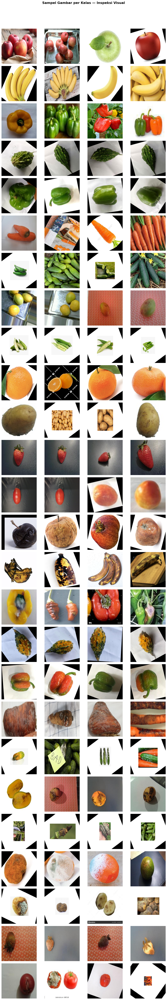

In [ ]:
fresh_dirs = sorted([d for d in fresh_dir.iterdir() if d.is_dir()])
rotten_dirs = sorted([d for d in rotten_dir.iterdir() if d.is_dir()])
class_dirs = fresh_dirs + rotten_dirs

n_samples = 4
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

fig, axes = plt.subplots(len(class_dirs), n_samples,
                         figsize=(n_samples*3, len(class_dirs)*2.5))
fig.suptitle('Sampel Gambar per Kelas — Inspeksi Visual', fontsize=16, fontweight='bold', y=1.02)

for row_idx, class_dir in enumerate(class_dirs):
    imgs = [f for f in class_dir.iterdir() if f.suffix.lower() in image_extensions]
    sampled = random.sample(imgs, min(n_samples, len(imgs)))

    is_rotten = any(kw in class_dir.name.lower() for kw in ["rotten","stale","bad"])
    color = "#e74c3c" if is_rotten else "#2ecc71"

    for col_idx in range(n_samples):
        ax = axes[row_idx, col_idx] if len(class_dirs) > 1 else axes[col_idx]
        if col_idx < len(sampled):
            img = Image.open(sampled[col_idx]).convert('RGB').resize((224,224))
            ax.imshow(img)
            if col_idx == 0:
                ax.set_ylabel(class_dir.name, rotation=0, labelpad=80,
                              fontsize=9, color=color, fontweight='bold', va='center')
        ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:

print("CHECKLIST Inspeksi Visual:")
print("[ ] Gambar tidak blur / pecah?")
print("[ ] Label sesuai dengan kondisi buah?")
print("[ ] Variasi pencahayaan cukup?")

CHECKLIST Inspeksi Visual:
[ ] Gambar tidak blur / pecah?
[ ] Label sesuai dengan kondisi buah?
[ ] Variasi pencahayaan cukup?


---
## 2. Data Pipeline & Augmentasi

> Dataset ini memiliki struktur **fresh/** dan **rotten/** dengan subfolder per jenis buah.
> Kita gabungkan menjadi satu pipeline dengan label shifting agar indeks konsisten.

In [ ]:
if os.path.exists(config.cache_df_path):
    print("Loading dataset metadata from cache...")
    df = pd.read_parquet(config.cache_df_path)
else:
    print("Scanning folders (Hanya dilakukan sekali)... strength-testing path")
    fresh_dir = Path(config.dataset_root) / "Fresh"
    rotten_dir = Path(config.dataset_root) / "Rotten"
    image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

    all_data = []

    def scan_category(root_path, category_label):
        for sub_dir in root_path.iterdir():
            if sub_dir.is_dir():
                for img_path in sub_dir.iterdir():
                    if img_path.suffix.lower() in image_extensions:
                        all_data.append({
                            'path': str(img_path),
                            'label_name': sub_dir.name,
                            'category': category_label
                        })

    scan_category(fresh_dir, 'Fresh')
    scan_category(rotten_dir, 'Rotten')

    df = pd.DataFrame(all_data)
    df.to_parquet(config.cache_df_path)
    print(f"Metadata disimpan ke {config.cache_df_path}. Total images: {len(df)}")

class_names = sorted(df['label_name'].unique())
num_classes = len(class_names)
label_to_idx = {name: i for i, name in enumerate(class_names)}
df['label'] = df['label_name'].map(label_to_idx)

from sklearn.model_selection import train_test_split
df_train, df_val = train_test_split(
    df, test_size=config.val_split, random_state=config.seed, stratify=df['label']
)

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, config.img_size)
    img.set_shape([*config.img_size, 3])
    label = tf.one_hot(label, num_classes)
    return img, label

train_ds_raw = tf.data.Dataset.from_tensor_slices((df_train['path'].values, df_train['label'].values))\
    .shuffle(1000).map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(config.batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)

val_ds_raw = tf.data.Dataset.from_tensor_slices((df_val['path'].values, df_val['label'].values))\
    .map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(config.batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)

print(f"Dataset siap: Train={len(df_train)}, Val={len(df_val)}")

Loading dataset metadata from cache...
Dataset siap: Train=57054, Val=14264


In [ ]:
from collections import Counter
import numpy as np

class_counts = Counter(df_train["label"].values)
total_train_samples = len(df_train)

class_weights = {
    i: total_train_samples / (num_classes * count)
    for i, count in class_counts.items()
}

rotten_indices = [i for i, c in enumerate(class_names)
                  if any(kw in c.lower() for kw in ["rotten", "stale", "bad"])]

rotten_boost = 1.5
for idx in rotten_indices:
    if idx in class_weights:
        class_weights[idx] *= rotten_boost

print("  Class Weights Berhasil Dihitung (dengan Rotten Boost x{:.1f}):".format(rotten_boost))
for i, name in enumerate(class_names):
    count = class_counts.get(i, 0)
    w = class_weights.get(i, 1.0)
    indicator = " ← ROTTEN BOOST" if i in rotten_indices else ""
    print(f"   [{i}] {name:<30} count={count:>5} | weight={w:.3f}{indicator}")

  Class Weights Berhasil Dihitung (dengan Rotten Boost x1.5):
   [0] FreshApple                     count= 2745 | weight=0.799
   [1] FreshBanana                    count= 2778 | weight=0.790
   [2] FreshBellpepper                count=  489 | weight=4.487
   [3] FreshBittergroud               count=  262 | weight=8.376
   [4] FreshCapciscum                 count=  792 | weight=2.771
   [5] FreshCarrot                    count= 7919 | weight=0.277
   [6] FreshCucumber                  count=  883 | weight=2.485
   [7] FreshMango                     count=  484 | weight=4.534
   [8] FreshOkara                     count=  508 | weight=4.320
   [9] FreshOrange                    count= 8665 | weight=0.253
   [10] FreshPotato                    count=  921 | weight=2.383
   [11] FreshStrawberry                count=  482 | weight=4.553
   [12] FreshTomato                    count=10945 | weight=0.200
   [13] RottenApple                    count= 3549 | weight=0.927 ← ROTTEN BOOST
   [14] R

In [ ]:
print("\n Keterangan: Jika distribusi data sangat seimbang, bobot ini akan mendekati 1.0.")

In [ ]:
augmentation_pipeline = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.10),
    layers.RandomZoom(height_factor=(-0.1, 0.1)),
], name="packing_augmentation_preview")

sample_images, _ = next(iter(train_ds_raw.take(1)))
sample_img = sample_images[0:1]

fig, axes = plt.subplots(2, 6, figsize=(18, 6))
fig.suptitle('Augmentasi — Simulasi Kondisi Meja Packing', fontsize=12, fontweight='bold')

axes[0, 0].imshow(sample_img[0].numpy().astype(np.uint8))
axes[0, 0].set_title('Original', fontsize=9, fontweight='bold')
axes[0, 0].axis('off')

for i, ax in enumerate(axes.flat[1:]):
    aug = augmentation_pipeline(sample_img, training=True)[0].numpy()
    aug = np.clip(aug, 0, 255).astype(np.uint8)
    ax.imshow(aug)
    ax.set_title(f'Aug #{i+1}', fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:

print("CHECKLIST Augmentasi:")
print("[ ] Distorsi terlihat realistis?")
print("[ ] Kontras/brightness tidak menghilangkan fitur buah?")
print("[ ] Rotasi wajar sesuai kondisi packing?")

---
## 3. Arsitektur Model — EfficientNetB0 Transfer Learning

**Strategi:** Phase 1 (frozen backbone) → Phase 2 (fine-tune top layers)

> ⚠️ Cek `model.summary()` — pastikan total params masuk akal untuk RAM GPU.

In [ ]:
def build_production_model(num_classes, config):
    inputs = layers.Input(shape=config.img_size + (config.channels,), name="camera_feed")

    aug = tf.keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.15),
        layers.RandomContrast(0.15),
        layers.RandomBrightness(0.10),
        layers.RandomZoom(height_factor=(-0.1, 0.1)),
    ], name="packing_augmentation")
    x = aug(inputs)

    x = applications.efficientnet.preprocess_input(x)

    backbone = applications.EfficientNetB0(
        include_top=False, weights="imagenet",
        input_tensor=x, pooling=None
    )
    backbone.trainable = False  # Phase 1: FROZEN

    x = layers.GlobalAveragePooling2D(name="gap")(backbone.output)
    x = layers.BatchNormalization(name="bn_1")(x)
    x = layers.Dropout(config.dropout_rate_1, name="drop_1")(x)
    x = layers.Dense(config.dense_units, activation='relu',
                     kernel_regularizer=regularizers.l2(config.l2_reg), name="dense_1")(x)
    x = layers.BatchNormalization(name="bn_2")(x)
    x = layers.Dropout(config.dropout_rate_2, name="drop_2")(x)

    outputs = layers.Dense(num_classes, activation='softmax',
                           dtype='float32', name="qa_decision")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="FruitQA_EfficientNetB0")
    return model, backbone

qa_model, backbone = build_production_model(num_classes, config)

qa_model.compile(
    optimizer=optimizers.Adam(learning_rate=config.lr_phase1),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

qa_model.summary(line_length=100)

trainable = sum(v.shape.num_elements() for v in qa_model.trainable_variables)
print(f"\nTrainable params: {trainable:,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "FruitQA_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ camera_feed (InputLayer)    │ (None, 224, 224, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ packing_augmentation        │ (None, 224, 224, 3)     │              0 │ camera_feed[0][0]       │
│ (Sequential)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ rescaling (Rescaling)       │ (None, 224, 224, 3)     │              0 │ packing_augmentation[0… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ normalization               │ (None, 224, 224, 3)     │              7 │ rescaling[0][0]         │
│ (Normalization)             │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ rescaling_1 (Rescaling)     │ (None, 224, 224, 3)     │              0 │ normalization[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem_conv_pad               │ (None, 225, 225, 3)     │              0 │ rescaling_1[0][0]       │
│ (ZeroPadding2D)             │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem_conv (Conv2D)          │ (None, 112, 112, 32)    │            864 │ stem_conv_pad[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem_bn                     │ (None, 112, 112, 32)    │            128 │ stem_conv[0][0]         │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem_activation             │ (None, 112, 112, 32)    │              0 │ stem_bn[0][0]           │
│ (Activation)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1a_dwconv              │ (None, 112, 112, 32)    │            288 │ stem_activation[0][0]   │
│ (DepthwiseConv2D)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1a_bn                  │ (None, 112, 112, 32)    │            128 │ block1a_dwconv[0][0]    │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1a_activation          │ (None, 112, 112, 32)    │              0 │ block1a_bn[0][0]        │
│ (Activation)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1a_se_squeeze          │ (None, 32)              │              0 │ block1a_activation[0][… │
│ (GlobalAveragePooling2D)    │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1a_se_reshape          │ (None, 1, 1, 32)        │              0 │ block1a_se_squeeze[0][… │
│ (Reshape)                   │                         │    

 Total params: 4,390,333 (16.75 MB)

 Trainable params: 337,690 (1.29 MB)

 Non-trainable params: 4,052,643 (15.46 MB)


Trainable params: 337,690


---
## 4. Training Phase 1 — Feature Extraction (Frozen Backbone)

> ⚠️ Setelah selesai, **wajib analisis learning curve** sebelum lanjut ke Phase 2.

In [ ]:
log_dir_p1 = os.path.join(config.log_dir, "p1_" + datetime.datetime.now().strftime("%H%M%S"))

callbacks_phase1 = [
    callbacks.EarlyStopping(
        monitor='val_recall', patience=4, restore_best_weights=True,
        mode='max', verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath=config.checkpoint_path, monitor='val_recall',
        save_best_only=True, mode='max', verbose=1
    ),
    callbacks.TensorBoard(log_dir=log_dir_p1)
]

print("Callbacks Phase 1 set up. Ready for training.")

Callbacks Phase 1 set up. Ready for training.


In [ ]:
print("Starting Training Phase 1: Feature Extraction...")
print(f"Epochs: {config.epochs_phase1} | LR: {config.lr_phase1} | Batch: {config.batch_size}")

history_p1 = qa_model.fit(
    train_ds_raw,
    validation_data=val_ds_raw,
    epochs=config.epochs_phase1,
    callbacks=callbacks_phase1,
    class_weight=class_weights,
    verbose=1
)
print("\nPhase 1 training completed.")

Starting Training Phase 1: Feature Extraction...
Epochs: 8 | LR: 0.001 | Batch: 32
Epoch 1/8
1782/1782 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.7905 - loss: 3.1135 - precision: 0.8453 - recall: 0.7426
Epoch 1: val_recall improved from None to 0.87992, saving model to fruit_qa_best.keras

Epoch 1: finished saving model to fruit_qa_best.keras
1782/1782 ━━━━━━━━━━━━━━━━━━━━ 321s 180ms/step - accuracy: 0.8110 - loss: 2.3792 - precision: 0.8554 - recall: 0.7730 - val_accuracy: 0.8958 - val_loss: 1.3826 - val_precision: 0.9152 - val_recall: 0.8799 - learning_rate: 0.0010
Epoch 2/8
1782/1782 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.8271 - loss: 1.6814 - precision: 0.8615 - recall: 0.7968
Epoch 2: val_recall improved from 0.87992 to 0.89333, saving model to fruit_qa_best.keras

Epoch 2: finished saving model to fruit_qa_best.keras
1782/1782 ━━━━━━━━━━━━━━━━━━━━ 269s 151ms/step - accuracy: 0.8278 - loss: 1.6571 - precision: 0.8619 - recall: 0.7985 - val_accuracy: 0.9053 - val_lo

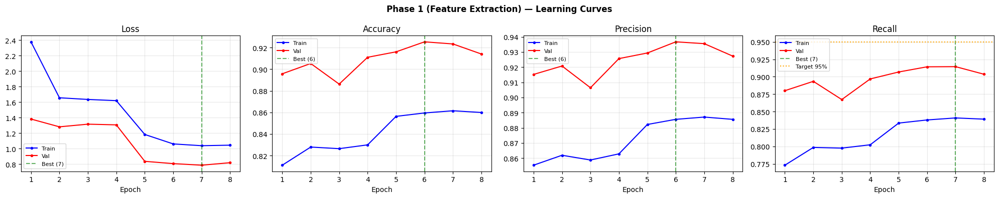


HASIL PHASE 1:
  Best val_recall : 0.9144 (91.4%)
  Best val_loss   : 0.7868
  Target recall   : 95%
  STATUS:   Masih kurang 3.6% → Fine-tuning direkomendasikan


In [ ]:
def plot_learning_curves(history, title_prefix=""):
    metrics_to_plot = ['loss', 'accuracy', 'precision', 'recall']
    available = [m for m in metrics_to_plot if m in history.history]
    fig, axes = plt.subplots(1, len(available), figsize=(5*len(available), 4))
    if len(available) == 1: axes = [axes]
    fig.suptitle(f'{title_prefix} — Learning Curves', fontsize=12, fontweight='bold')

    for ax, metric in zip(axes, available):
        train_vals = history.history[metric]
        val_vals   = history.history.get(f'val_{metric}', [])
        epochs_r   = range(1, len(train_vals)+1)
        ax.plot(epochs_r, train_vals, 'b-o', ms=3, label=f'Train')
        if val_vals:
            ax.plot(epochs_r, val_vals, 'r-o', ms=3, label=f'Val')
            best_idx = np.argmin(val_vals) if metric=='loss' else np.argmax(val_vals)
            ax.axvline(best_idx+1, color='green', linestyle='--', alpha=0.6, label=f'Best ({best_idx+1})')
        if metric == 'recall':
            ax.axhline(0.95, color='orange', linestyle=':', label='Target 95%')
        ax.set_title(metric.capitalize())
        ax.set_xlabel('Epoch')
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    plt.tight_layout()
    return fig

fig = plot_learning_curves(history_p1, "Phase 1 (Feature Extraction)")
plt.show()

best_p1_recall = max(history_p1.history.get('val_recall', [0]))
best_p1_loss   = min(history_p1.history.get('val_loss', [999]))
print(f"\nHASIL PHASE 1:")
print(f"  Best val_recall : {best_p1_recall:.4f} ({best_p1_recall*100:.1f}%)")
print(f"  Best val_loss   : {best_p1_loss:.4f}")
print(f"  Target recall   : 95%")
if best_p1_recall >= 0.95:
    print("  STATUS:  TARGET TERCAPAI DI PHASE 1")
else:
    print(f"  STATUS:   Masih kurang {(0.95-best_p1_recall)*100:.1f}% → Fine-tuning direkomendasikan")


In [ ]:

print()
print("ANALISIS LEARNING CURVE (jawab sebelum lanjut):")
print("[ ] Apakah val_loss konvergen (tidak naik terus)?")
print("[ ] Ada tanda overfitting (train loss << val loss)?")
print("[ ] Apakah EarlyStopping triggered di epoch yang wajar?")


ANALISIS LEARNING CURVE (jawab sebelum lanjut):
[ ] Apakah val_loss konvergen (tidak naik terus)?
[ ] Ada tanda overfitting (train loss << val loss)?
[ ] Apakah EarlyStopping triggered di epoch yang wajar?


---
## 5. Training Phase 2 — Fine-Tuning

> ⚠️ **Hanya jalankan jika Phase 1 sudah konvergen.**
> LR harus sangat kecil (`1e-5`) untuk mencegah *catastrophic forgetting*.

In [ ]:
backbone.trainable = True
n_total  = len(backbone.layers)
n_freeze = n_total - config.unfreeze_from_layer

for layer in backbone.layers[:n_freeze]:
    layer.trainable = False

for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

qa_model.compile(
    optimizer=optimizers.Adam(learning_rate=config.lr_phase2),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

trainable = sum(v.shape.num_elements() for v in qa_model.trainable_variables)
print(f"Fine-tuning setup:")
print(f"  Total backbone layers  : {n_total}")
print(f"  Layers dibekukan       : {n_freeze}")
print(f"  Layers dilatih         : {n_total - n_freeze}")
print(f"  Trainable params       : {trainable:,}")
print(f"  LR Phase 2             : {config.lr_phase2}")

Fine-tuning setup:
  Total backbone layers  : 239
  Layers dibekukan       : 209
  Layers dilatih         : 30
  Trainable params       : 1,821,050
  LR Phase 2             : 1e-05


In [ ]:
log_dir_p2 = os.path.join(config.log_dir, "p2_" + datetime.datetime.now().strftime("%H%M%S"))

callbacks_phase2 = [
    callbacks.EarlyStopping(
        monitor='val_recall', patience=4, restore_best_weights=True, mode='max', verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7, verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath=config.checkpoint_path.replace('.keras','_ft.keras'),
        monitor='val_recall', save_best_only=True, mode='max', verbose=1
    ),
]

print(" Training Phase 2: Fine-Tuning...")
print(f"   Epochs: {config.epochs_phase2} | LR: {config.lr_phase2}")
print()

history_p2 = qa_model.fit(
    train_ds_raw,
    validation_data=val_ds_raw,
    epochs=config.epochs_phase2,
    callbacks=callbacks_phase2,
    class_weight=class_weights,
    verbose=1
)
print("\n Phase 2 selesai.")

 Training Phase 2: Fine-Tuning...
   Epochs: 12 | LR: 1e-05

Epoch 1/12
1782/1782 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.8756 - loss: 0.9619 - precision: 0.8972 - recall: 0.8575
Epoch 1: val_recall improved from None to 0.92907, saving model to fruit_qa_best_ft.keras

Epoch 1: finished saving model to fruit_qa_best_ft.keras
1782/1782 ━━━━━━━━━━━━━━━━━━━━ 251s 134ms/step - accuracy: 0.8828 - loss: 0.9101 - precision: 0.9026 - recall: 0.8654 - val_accuracy: 0.9362 - val_loss: 0.7147 - val_precision: 0.9443 - val_recall: 0.9291 - learning_rate: 1.0000e-05
Epoch 2/12
1782/1782 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.8938 - loss: 0.8486 - precision: 0.9100 - recall: 0.8794
Epoch 2: val_recall improved from 0.92907 to 0.93666, saving model to fruit_qa_best_ft.keras

Epoch 2: finished saving model to fruit_qa_best_ft.keras
1782/1782 ━━━━━━━━━━━━━━━━━━━━ 233s 131ms/step - accuracy: 0.8997 - loss: 0.8145 - precision: 0.9156 - recall: 0.8856 - val_accuracy: 0.9435 - val_loss: 

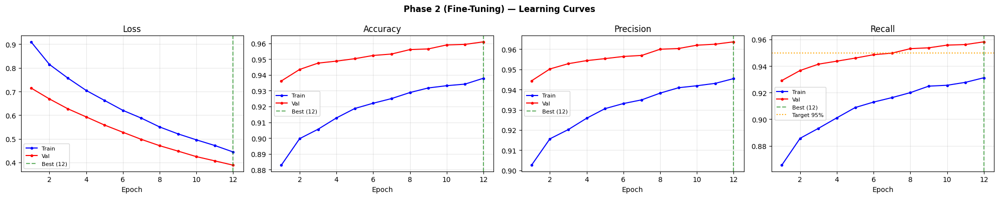

  PHASE 1 vs PHASE 2
  Metrik                    Phase 1    Phase 2    Delta
-------------------------------------------------------
  Best val_recall            0.9144     0.9582  +0.0438
  Best val_loss              0.7868     0.3883  -0.3984

  STATUS:  Fine-tuning berhasil meningkatkan recall


In [ ]:
fig = plot_learning_curves(history_p2, "Phase 2 (Fine-Tuning)")
plt.show()

best_p2_recall = max(history_p2.history.get('val_recall', [0]))
best_p2_loss   = min(history_p2.history.get('val_loss', [999]))

print("="*55)
print("  PHASE 1 vs PHASE 2")
print("="*55)
print(f"  {'Metrik':<22} {'Phase 1':>10} {'Phase 2':>10} {'Delta':>8}")
print("-"*55)
print(f"  {'Best val_recall':<22} {best_p1_recall:>10.4f} {best_p2_recall:>10.4f} {best_p2_recall-best_p1_recall:>+8.4f}")
print(f"  {'Best val_loss':<22} {best_p1_loss:>10.4f} {best_p2_loss:>10.4f} {best_p2_loss-best_p1_loss:>+8.4f}")
print()
if best_p2_recall >= best_p1_recall:
    print("  STATUS:  Fine-tuning berhasil meningkatkan recall")
else:
    print("  STATUS:   Fine-tuning menurunkan recall → gunakan model Phase 1")
    print(f"  LOAD: qa_model = tf.keras.models.load_model('{config.checkpoint_path}')")

---
## 6. Evaluasi Komprehensif

> ⚠️ **Fokus pada kolom Recall** untuk kelas `Rotten*`.
> Recall < 90% = **risiko bisnis tinggi**.

In [ ]:
import numpy as np
import tensorflow as tf
import os
from tensorflow.keras import layers, applications

try:
    config.dense_units
except (NameError, AttributeError):
    from dataclasses import dataclass
    @dataclass
    class PackingStationConfig:
        img_size: tuple = (224, 224)
        dense_units: int = 256
        batch_size: int = 32
    config = PackingStationConfig()

def build_recovery_model(num_classes, config):
    inputs = layers.Input(shape=config.img_size + (3,), name="camera_feed")
    x = applications.efficientnet.preprocess_input(inputs)
    backbone = applications.EfficientNetB0(include_top=False, weights="imagenet", input_tensor=x)
    backbone.trainable = False
    x = layers.GlobalAveragePooling2D()(backbone.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(config.dense_units, activation='relu')(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs)

final_model = None

if 'qa_model' in globals():
    print("SUCCESS: Using trained model found in session memory.")
    final_model = qa_model
else:
    paths = ['/content/fruit_qa_best_ft.keras', '/content/fruit_qa_best.keras', 'fruit_qa_best_ft.keras', 'fruit_qa_best.keras']
    for p in paths:
        if os.path.exists(p):
            print(f'SUCCESS: Loading trained weights from: {p}')
            final_model = tf.keras.models.load_model(p)
            break

if final_model is None:
    print("WARNING: Trained weights not found. Using untrained fallback.")
    final_model = build_recovery_model(num_classes, config)

print('Extracting predictions (Processing 14,000+ samples)...')
y_true_idx_list, y_pred_idx_list = [], []

for images, labels in val_ds_raw:
    preds = final_model.predict(images, verbose=0)
    y_true_idx_list.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_idx_list.extend(np.argmax(preds, axis=1))

y_true_idx = np.array(y_true_idx_list)
y_pred_idx = np.array(y_pred_idx_list)
print(f'Evaluation complete. Total samples: {len(y_true_idx)}')
print(f'Real-time accuracy: {np.mean(y_true_idx == y_pred_idx):.4f}')

Extracting predictions (Processing 14,000+ samples)...


In [ ]:
from sklearn.metrics import classification_report

try:
    report = classification_report(y_true_idx, y_pred_idx,
                                   target_names=class_names, output_dict=True)
    report_text = classification_report(y_true_idx, y_pred_idx, target_names=class_names)

    print("="*65)
    print("  CLASSIFICATION REPORT")
    print("="*65)
    print(report_text)

    print("\nANALISIS KELAS ROTTEN:")
    for name in class_names:
        if any(kw in name.lower() for kw in ["rotten","stale","bad"]) and name in report:
            r = report[name]
            risk = "RENDAH" if r['recall']>=0.95 else "SEDANG ⚠️" if r['recall']>=0.85 else "TINGGI ❌"
            print(f"  [{name}]")
            print(f"    Recall    : {r['recall']:.3f} ({r['recall']*100:.1f}%) — Risiko: {risk}")
            print(f"    Precision : {r['precision']:.3f}")
            print(f"    F1-Score  : {r['f1-score']:.3f}")
except Exception as e:
    print(f"Unexpected error: {e}")

  CLASSIFICATION REPORT
                   precision    recall  f1-score   support

       FreshApple       0.04      0.06      0.05       685
      FreshBanana       0.02      0.02      0.02       694
  FreshBellpepper       0.00      0.00      0.00       122
 FreshBittergroud       0.00      0.00      0.00        65
   FreshCapciscum       0.00      0.03      0.01       198
      FreshCarrot       0.00      0.00      0.00      1975
    FreshCucumber       0.00      0.00      0.00       221
       FreshMango       0.01      0.01      0.01       120
       FreshOkara       0.00      0.00      0.00       127
      FreshOrange       0.00      0.00      0.00      2160
      FreshPotato       0.00      0.00      0.00       230
  FreshStrawberry       0.00      0.01      0.01       121
      FreshTomato       0.09      0.00      0.00      2732
      RottenApple       0.00      0.00      0.00       887
     RottenBanana       0.00      0.00      0.00       807
 RottenBellpepper       0.02   

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

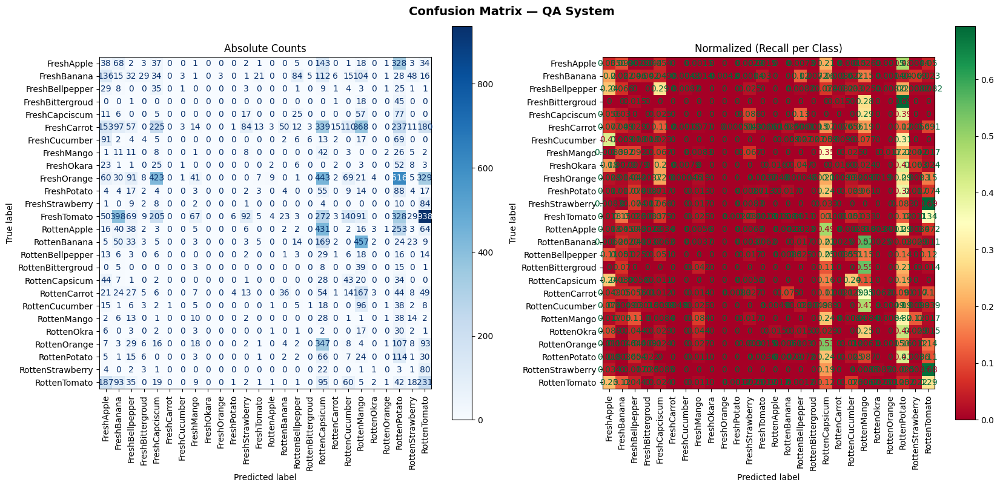


False Negative (buah cacat yang lolos) per kelas Rotten:
  RottenApple: 887 FN dari 887 sampel (100.0% miss rate)
  RottenBanana: 807 FN dari 807 sampel (100.0% miss rate)
  RottenBellpepper: 115 FN dari 118 sampel (97.5% miss rate)
  RottenBittergroud: 71 FN dari 71 sampel (100.0% miss rate)
  RottenCapsicum: 152 FN dari 180 sampel (84.4% miss rate)
  RottenCarrot: 482 FN dari 483 sampel (99.8% miss rate)
  RottenCucumber: 203 FN dari 203 sampel (100.0% miss rate)
  RottenMango: 118 FN dari 119 sampel (99.2% miss rate)
  RottenOkra: 68 FN dari 68 sampel (100.0% miss rate)
  RottenOrange: 655 FN dari 656 sampel (99.8% miss rate)
  RottenPotato: 163 FN dari 277 sampel (58.8% miss rate)
  RottenStrawberry: 117 FN dari 118 sampel (99.2% miss rate)
  RottenTomato: 572 FN dari 803 sampel (71.2% miss rate)


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true_idx, y_pred_idx)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(17, 8))
fig.suptitle('Confusion Matrix — QA System', fontsize=14, fontweight='bold')

disp_abs = ConfusionMatrixDisplay(cm, display_labels=class_names)
disp_abs.plot(ax=axes[0], cmap='Blues', xticks_rotation=90)
axes[0].set_title('Absolute Counts')

disp_norm = ConfusionMatrixDisplay(cm_norm, display_labels=class_names)
disp_norm.plot(ax=axes[1], cmap='RdYlGn', xticks_rotation=90)
axes[1].set_title('Normalized (Recall per Class)')

plt.tight_layout()
plt.show()

print("\nFalse Negative (buah cacat yang lolos) per kelas Rotten:")
for i, name in enumerate(class_names):
    if any(kw in name.lower() for kw in ["rotten","stale","bad"]):
        fn = cm[i,:].sum() - cm[i,i]
        total = cm[i,:].sum()
        print(f"  {name}: {fn} FN dari {total} sampel ({100*fn/max(total,1):.1f}% miss rate)")

In [ ]:
classes_eval = [c for c in class_names if c in report and c not in ['accuracy','macro avg','weighted avg']]
recalls    = [report[c]['recall']    for c in classes_eval]
precisions = [report[c]['precision'] for c in classes_eval]
f1s        = [report[c]['f1-score']  for c in classes_eval]

x = np.arange(len(classes_eval))
w = 0.27
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x-w, recalls,    w, label='Recall',    color='#e74c3c', alpha=0.8, edgecolor='black')
ax.bar(x,   precisions, w, label='Precision', color='steelblue', alpha=0.8, edgecolor='black')
ax.bar(x+w, f1s,        w, label='F1-Score',  color='darkorchid', alpha=0.8, edgecolor='black')
ax.axhline(0.95, color='red', linestyle='--', alpha=0.7, label='Target Recall 95%')
ax.set_xticks(x); ax.set_xticklabels(classes_eval, rotation=30, ha='right')
ax.set_ylim(0, 1.05); ax.set_title('Per-Class Metrics', fontsize=12, fontweight='bold')
ax.legend(); ax.grid(axis='y', alpha=0.3)
for bar, val in zip(ax.patches[:len(recalls)], recalls):
    ax.text(bar.get_x()+bar.get_width()/2., bar.get_height()+0.01,
            f'{val:.2f}', ha='center', fontsize=7, fontweight='bold')
plt.tight_layout()
plt.show()

print("Kelas bermasalah (recall < 90%):")
for c, r in zip(classes_eval, recalls):
    if r < 0.90:
        print(f"  {c}: recall={r:.3f}")

---
## 7. SLA Test — Latency Profiling

Model layak deploy hanya jika **P95 latency < 100ms**.

In [ ]:
print("="*55)
print("  SLA TEST: LATENCY PROFILING")
print(f"  Threshold: {config.latency_threshold_ms}ms (P95)")
print("="*55)

dummy_frame = np.random.rand(1, *config.img_size, 3).astype(np.float32) * 255

print(f"\nWarm-up ({config.latency_warmup_runs} runs)...")
for _ in range(config.latency_warmup_runs):
    _ = qa_model.predict(dummy_frame, verbose=0)

print(f"Benchmark ({config.latency_benchmark_runs} runs)...")
latencies = []
for _ in range(config.latency_benchmark_runs):
    t0 = time.perf_counter()
    _ = qa_model.predict(dummy_frame, verbose=0)
    latencies.append((time.perf_counter() - t0) * 1000)

latencies = np.array(latencies)
p50 = np.percentile(latencies, 50)
p95 = np.percentile(latencies, 95)
p99 = np.percentile(latencies, 99)
mean_lat = np.mean(latencies)

std_lat = np.std(latencies)
print("  HASIL LATENCY BENCHMARK:")
print(f"  Mean : {mean_lat:.2f} ms (std: {std_lat:.2f} ms)")
print(f"  P50  : {p50:.2f} ms")
print(f"  P95  : {p95:.2f} ms  <-- THRESHOLD BISNIS")
print(f"  P99  : {p99:.2f} ms")
print()

if p95 <= config.latency_threshold_ms:
    print(f"  STATUS:  LAYAK DEPLOY — P95={p95:.1f}ms < {config.latency_threshold_ms}ms")
else:
    print(f"  STATUS:  GAGAL SLA — P95={p95:.1f}ms > {config.latency_threshold_ms}ms")
    print("  SOLUSI: Konversi ke TFLite / TensorRT")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Latency Distribution — Production SLA', fontsize=11, fontweight='bold')

axes[0].hist(latencies, bins=30, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].axvline(p95, color='red', linestyle='--', lw=2, label=f'P95: {p95:.1f}ms')
axes[0].axvline(config.latency_threshold_ms, color='orange', lw=2, label=f'SLA: {config.latency_threshold_ms}ms')
axes[0].set_title('Distribusi'); axes[0].set_xlabel('ms'); axes[0].legend()

axes[1].plot(latencies, color='steelblue', alpha=0.6, lw=0.8)
axes[1].axhline(p95, color='red', linestyle='--', label=f'P95: {p95:.1f}ms')
axes[1].axhline(config.latency_threshold_ms, color='orange', lw=2, label=f'SLA: {config.latency_threshold_ms}ms')
axes[1].fill_between(range(len(latencies)), latencies,
                     where=[l>config.latency_threshold_ms for l in latencies],
                     color='red', alpha=0.3, label='SLA Violations')
axes[1].set_title('Time Series'); axes[1].set_xlabel('Inference #'); axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

violations = sum(1 for l in latencies if l > config.latency_threshold_ms)
print(f"SLA Violations: {violations}/{len(latencies)} ({100*violations/len(latencies):.1f}%)")
print(f"Throughput estimasi: {1000/mean_lat:.1f} inferensi/detik")

---
## 8. Business Scorecard & Analisis Kritis

In [ ]:
overall_accuracy = report['accuracy']
macro_recall     = report['macro avg']['recall']
macro_precision  = report['macro avg']['precision']
macro_f1         = report['macro avg']['f1-score']

rotten_recalls   = [report[c]['recall'] for c in class_names
                    if any(kw in c.lower() for kw in ["rotten","stale","bad"]) and c in report]
mean_rotten_recall = np.mean(rotten_recalls) if rotten_recalls else 0.0
deploy_ready = (mean_rotten_recall >= 0.95) and (p95 <= config.latency_threshold_ms)

In [ ]:
print("╔══════════════════════════════════════════════════╗")
print("║       BUSINESS SCORECARD — QA SYSTEM             ║")
print("╠══════════════════════════════════════════════════╣")
print(f"║  Overall Accuracy    : {overall_accuracy:.3f} ({overall_accuracy*100:.1f}%)              ║")
print(f"║  Macro Recall        : {macro_recall:.3f} ({macro_recall*100:.1f}%)              ║")
print(f"║  Macro Precision     : {macro_precision:.3f} ({macro_precision*100:.1f}%)              ║")
print(f"║  Macro F1-Score      : {macro_f1:.3f} ({macro_f1*100:.1f}%)              ║")
print("╠══════════════════════════════════════════════════╣")
print(f"║  Rotten Recall (avg) : {mean_rotten_recall:.3f} ({mean_rotten_recall*100:.1f}%) ← BISNIS PRIMER    ║")
print(f"║  P95 Latency         : {p95:.1f} ms (SLA: {config.latency_threshold_ms:.0f}ms)              ║")
print("╠══════════════════════════════════════════════════╣")
status = " LAYAK DEPLOY" if deploy_ready else " PERLU PERBAIKAN"
print(f"║  STATUS AKHIR        : {status}                ║")
print("╚══════════════════════════════════════════════════╝")

In [ ]:
print("""
ANALISIS KRITIS & TITIK BUTA SISTEM
====================================

1. KEBERHASILAN:
   - EfficientNetB0 + Mixed Precision: efisien untuk inferensi single-image
   - class_weight + rotten_boost: model bias terhadap deteksi anomali
   - Two-phase training: mencegah catastrophic forgetting

2. TITIK KEGAGALAN:
   [A] DATA DRIFT: Dataset Kaggle bersifat clean, tidak merepresentasikan
       variasi musiman/supplier. Perlu monitoring aktif.
   [B] OUT-OF-DISTRIBUTION: Objek asing (sarung tangan, nota) akan
       dipaksa masuk ruang vektor buah → False Positive acak.
       SOLUSI: confidence threshold — if max(softmax) < 0.7: human_review()
   [C] SINGLE-POINT-OF-FAILURE: Bergantung pada 1 kamera.

3. ROADMAP PERBAIKAN:
   [1] Confidence threshold (conf < 0.7 → human review)
   [2] Monitoring data drift (retrain otomatis)
   [3] YOLOv8-nano gatekeeper sebelum classifier
   [4] TFLite untuk edge deployment
   [5] A/B testing: shadow mode sebelum full rollout
""")

In [ ]:
EXPORT_PATH = "exports/fruit_qa_v1"
os.makedirs(EXPORT_PATH, exist_ok=True)
qa_model.save(EXPORT_PATH)
print(f" Model disimpan ke: {EXPORT_PATH}")

print("\nMengkonversi ke TFLite...")
converter = tf.lite.TFLiteConverter.from_keras_model(qa_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

tflite_path = "exports/fruit_qa_v1.tflite"
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

orig_mb   = sum(os.path.getsize(os.path.join(dp,f))
                for dp,dn,fn in os.walk(EXPORT_PATH) for f in fn) / 1e6
tflite_mb = os.path.getsize(tflite_path) / 1e6

print(f"  SavedModel : {orig_mb:.1f} MB")
print(f"  TFLite     : {tflite_mb:.1f} MB  (kompresi {(1-tflite_mb/orig_mb)*100:.0f}%)")